# Signal Lab · A trained stock-position model

**The submitted predictor is logistic regression with four learned feature
weights.** It uses five-day return, the 20/100-day Close-average ratio, recent
volatility, and relative volume. Its learned score maps to five possible target
positions: −1, −0.5, 0, +0.5, +1. This is the submitted model even if a benchmark
wins the comparison.

Run top to bottom. Fitting uses 2015–2022; practice evaluates 2023. Practice has
been viewed historically, so it is reused development evidence. This run does
not evaluate 2024. Only the organizer's hidden rounds are unseen final tests.

The event scores trading and explanation equally. It requires
`predict(history)` to return a Python float from −1 to 1 using only the supplied
prior OHLCV history. It trades at the next open with a 0.1% fee per transaction
side. The permitted development-data range is 2015–2024; no real data after
2024 may be used for training, testing, or model choice.


## 1 · Team and dependencies
Keep the real team name and 2–4 members below. Missing libraries install only when needed.


In [1]:
TEAM_NAME = "Signal Lab"
TEAM_MEMBERS = ["Cameron Penaranda", "Justin Paul Liporada"]

# Install only missing libraries, in one call; Colab usually already has them.
import importlib.util
import subprocess
import sys
_requirements = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
                 "sklearn": "scikit-learn", "cloudpickle": "cloudpickle"}
_missing = [package for module, package in _requirements.items()
            if importlib.util.find_spec(module) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)

# Keep the organizer's charts visible in Jupyter and Google Colab.
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass


## 2 · Original organizer setup
The complete official setup source below is unchanged, including its scoring and submission functions.


In [2]:
# @title ⚙️ Setup: run this, no need to open it
import hashlib, inspect, json, subprocess, sys, tempfile, time, types
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

try:
    import cloudpickle
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'cloudpickle'], check=True)
    import cloudpickle

try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'text.parse_math': False})

WORK_DIR = (Path('/content') if Path('/content').exists() else Path.cwd()) / 'trading_competition'
WORK_DIR.mkdir(parents=True, exist_ok=True)

# The exact scoring engine the organizers use on competition day.
HARNESS_SOURCE = '"""SDSU AI Club trading harness v1.0.\n\nShare this exact file with the organizer-side builder. The member notebook embeds\nthe same bytes. This is a deterministic backtest, not a security sandbox.\n"""\nfrom __future__ import annotations\n\nimport math\nimport time\nfrom typing import Callable\n\nimport numpy as np\nimport pandas as pd\n\nHARNESS_VERSION = \'sdsu-trading-harness-v1.0\'\nOHLCV = [\'Open\', \'High\', \'Low\', \'Close\', \'Volume\']\nFEE_RATE = 0.001\nWARMUP_BARS = 252\nTRADING_DAYS_PER_YEAR = 252\n\n\nclass ContractError(ValueError):\n    """The submitted prediction function broke the published contract."""\n\n\ndef clean_frame(frame: pd.DataFrame) -> pd.DataFrame:\n    """Validate a daily OHLCV frame without filling missing prices."""\n    result = frame.copy()\n    if \'Date\' in result.columns:\n        result = result.set_index(\'Date\')\n    result.index = pd.DatetimeIndex(pd.to_datetime(result.index))\n    if result.index.tz is not None:\n        result.index = result.index.tz_localize(None)\n    result.index = result.index.normalize()\n    result.index.name = \'Date\'\n    if result.index.has_duplicates:\n        raise ValueError(\'Duplicate dates: one stock must have one row per day.\')\n    missing = set(OHLCV) - set(result.columns)\n    if missing:\n        raise ValueError(f\'Missing OHLCV columns: {sorted(missing)}\')\n    result = result[OHLCV].sort_index().astype(float)\n    result.attrs = {}\n    if len(result) == 0 or not np.isfinite(result.to_numpy()).all():\n        raise ValueError(\'Data must contain finite OHLCV values; inspect missing rows.\')\n    if (result[[\'Open\', \'High\', \'Low\', \'Close\']] <= 0).any().any():\n        raise ValueError(\'Prices must be positive.\')\n    if (result[\'Volume\'] < 0).any():\n        raise ValueError(\'Volume cannot be negative.\')\n    if (result[\'High\'] + 1e-6 < result[[\'Open\', \'Close\', \'Low\']].max(axis=1)).any():\n        raise ValueError(\'A High value is below another price in the same bar.\')\n    if (result[\'Low\'] - 1e-6 > result[[\'Open\', \'Close\', \'High\']].min(axis=1)).any():\n        raise ValueError(\'A Low value is above another price in the same bar.\')\n    return result\n\n\ndef checked_position(result) -> float:\n    if isinstance(result, (bool, np.bool_)) or not isinstance(result, (float, np.floating)):\n        raise ContractError(\'predict(history) must return a float, e.g. return float(0.5).\')\n    result = float(result)\n    if not math.isfinite(result) or not -1.0 <= result <= 1.0:\n        raise ContractError(f\'Position {result!r} is not a finite float between -1 and 1.\')\n    return result\n\n\ndef smoke_check_predict(predict: Callable) -> dict:\n    """Check unseen dummy OHLCV input; this data is never used for training."""\n    rng = np.random.default_rng(812)\n    close = 100 * np.exp(np.cumsum(rng.normal(0, .008, WARMUP_BARS)))\n    history = pd.DataFrame({\n        \'Open\': close * .999,\n        \'High\': close * 1.01,\n        \'Low\': close * .99,\n        \'Close\': close,\n        \'Volume\': rng.integers(100_000, 1_000_000, WARMUP_BARS).astype(float),\n    }, index=pd.bdate_range(\'2020-01-02\', periods=WARMUP_BARS, name=\'Date\'))\n    before = history.copy(deep=True)\n    start = time.perf_counter()\n    first = checked_position(predict(history))\n    elapsed = time.perf_counter() - start\n    if not history.equals(before):\n        raise ContractError(\'predict() modified its input. Work on a copy instead.\')\n    second = checked_position(predict(before.copy(deep=True)))\n    if abs(first - second) > 1e-10:\n        raise ContractError(\'Identical histories must produce identical positions.\')\n    flat = before.copy()\n    flat[[\'Open\', \'High\', \'Low\', \'Close\']] = 100.0\n    checked_position(predict(flat))\n    return {\'dummy_position\': first, \'seconds_per_call\': round(elapsed, 4), \'passed\': True}\n\n\ndef _rebalance(cash: float, shares: float, price: float, target: float, fee: float):\n    """Solve for target exposure as a fraction of equity AFTER transaction fees."""\n    equity = cash + shares * price\n    if equity <= 0:\n        raise ContractError(\'A stock allocation became insolvent (equity <= 0).\')\n    gap = target * equity - shares * price\n    denominator = 1.0 + target * fee if gap >= 0 else 1.0 - target * fee\n    notional = gap / denominator\n    cost = fee * abs(notional)\n    cash -= notional + cost\n    shares += notional / price\n    after = cash + shares * price\n    if after <= 0:\n        raise ContractError(\'Transaction fees exhausted a stock allocation.\')\n    if abs(shares * price) > after * (1 + 1e-9):\n        raise ContractError(\'Gross exposure exceeded the no-leverage limit.\')\n    return cash, shares, cost, abs(notional)\n\n\ndef performance_metrics(equity: pd.Series) -> dict:\n    daily = equity.pct_change().dropna()\n    sigma = float(daily.std(ddof=1)) if len(daily) >= 2 else 0.0\n    sharpe = float(np.sqrt(TRADING_DAYS_PER_YEAR) * daily.mean() / sigma) if sigma > 1e-12 else 0.0\n    drawdown = equity / equity.cummax() - 1\n    return {\n        \'Sharpe\': sharpe,\n        \'Total return\': float(equity.iloc[-1] / equity.iloc[0] - 1),\n        \'Max drawdown\': float(drawdown.min()),\n        \'Final equity\': float(equity.iloc[-1]),\n        \'Intervals\': int(len(daily)),\n    }\n\n\ndef run_backtest(data: dict, predict: Callable, start: str, end: str,\n                 initial_capital: float = 10_000.0, fee_rate: float = FEE_RATE,\n                 warmup_bars: int = WARMUP_BARS, budget_seconds: float = 120.0) -> dict:\n    """Observe prior close -> trade next open -> mark at the following open.\n\n    `start` and `end` inclusively select execution/mark dates. The final selected\n    open liquidates all holdings; it is not an additional prediction date.\n    Each stock starts with an equal independent allocation. Allocations are not\n    rebalanced across stocks. No interest, dividends, borrow charges, or slippage\n    beyond the specified fee are separately credited/debited.\n    """\n    if not data or initial_capital <= 0 or not 0 <= fee_rate < .1:\n        raise ValueError(\'Supply stock data, positive capital, and a valid fee rate.\')\n    frames = {str(name): clean_frame(frame) for name, frame in data.items()}\n    dates = None\n    for frame in frames.values():\n        dates = frame.index if dates is None else dates.intersection(frame.index)\n    dates = dates[(dates >= pd.Timestamp(start)) & (dates <= pd.Timestamp(end))].sort_values()\n    if len(dates) < 3:\n        raise ValueError(\'Choose a window containing at least three common trading dates.\')\n    deadline = time.perf_counter() + budget_seconds\n    allocation = initial_capital / len(frames)\n    curves, trades = {}, []\n    total_fees = 0.0\n    for name, frame in frames.items():\n        first = frame.index.get_loc(dates[0])\n        if first < warmup_bars:\n            raise ValueError(f\'{name}: need {warmup_bars} earlier bars before the window starts.\')\n        history_start = first - warmup_bars\n        cash, shares = float(allocation), 0.0\n        values = [allocation]\n        for k, date in enumerate(dates[:-1]):\n            if time.perf_counter() > deadline:\n                raise TimeoutError(\'Local backtest budget exceeded. Simplify predict(); never train inside it.\')\n            at = frame.index.get_loc(date)\n            history = frame.iloc[history_start:at][OHLCV].copy(deep=True)\n            history.attrs = {}\n            position = checked_position(predict(history))\n            if time.perf_counter() > deadline:\n                raise TimeoutError(\'Local backtest budget exceeded during a prediction.\')\n            price = float(frame.at[date, \'Open\'])\n            cash, shares, cost, turnover = _rebalance(cash, shares, price, position, fee_rate)\n            total_fees += cost\n            if turnover > 1e-8:\n                trades.append({\'Stock\': name, \'Execution date\': date,\n                               \'History through\': history.index[-1], \'Target\': position,\n                               \'Notional traded\': turnover, \'Fee\': cost})\n            marked = cash + shares * float(frame.at[dates[k + 1], \'Open\'])\n            if marked <= 0:\n                raise ContractError(f\'{name}: a stock allocation became insolvent. Reduce exposure or shorting.\')\n            values.append(marked)\n        exit_price = float(frame.at[dates[-1], \'Open\'])\n        cash, shares, cost, turnover = _rebalance(cash, shares, exit_price, 0.0, fee_rate)\n        total_fees += cost\n        values[-1] = cash\n        if turnover > 1e-8:\n            trades.append({\'Stock\': name, \'Execution date\': dates[-1],\n                           \'History through\': pd.NaT, \'Target\': 0.0,\n                           \'Notional traded\': turnover, \'Fee\': cost})\n        curves[name] = pd.Series(values, index=dates)\n    by_stock = pd.DataFrame(curves)\n    equity = by_stock.sum(axis=1).rename(\'Portfolio equity\')\n    metrics = performance_metrics(equity)\n    metrics[\'Fees paid\'] = total_fees\n    metrics[\'Trades\'] = len(trades)\n    return {\'equity\': equity, \'daily_returns\': equity.pct_change().dropna(),\n            \'by_stock\': by_stock, \'trades\': pd.DataFrame(trades), \'metrics\': metrics,\n            \'harness_version\': HARNESS_VERSION}\n\n\ndef buy_and_hold(history: pd.DataFrame) -> float:\n    return 1.0\n'
harness = types.ModuleType('sdsu_harness')
exec(compile(HARNESS_SOURCE, 'sdsu_harness.py', 'exec'), harness.__dict__)
HARNESS_SHA = hashlib.sha256(HARNESS_SOURCE.encode()).hexdigest()

FIRST_ALLOWED, LAST_ALLOWED = pd.Timestamp('2015-01-01'), pd.Timestamp('2024-12-31')
PRACTICE_START, PRACTICE_END = '2023-01-01', '2023-12-31'
PRACTICE_STOCKS = ['AAPL', 'JPM', 'XOM', 'JNJ']
DATA = {}
ATTEMPTS = []
ROBUSTNESS_RUNS = []
_latest_training_end = None
STOCK_GROUPS = {
    'Big tech': ['AAPL', 'MSFT', 'NVDA', 'META'],
    'Steady': ['JNJ', 'PG', 'KO', 'DUK'],
    'Struggling': ['INTC', 'F', 'M', 'HOG'],
    'Volatile': ['PLUG', 'AAL', 'CROX', 'BA'],
}
TEST_YEARS_STOCKS = ['JPM', 'XOM', 'PFE', 'CROX', 'M']


def split_by_stock(prices):
    """Turn the long price table into {ticker: daily prices}."""
    prices = prices.copy()
    prices['Date'] = pd.to_datetime(prices['Date'])
    if prices['Date'].min() < FIRST_ALLOWED or prices['Date'].max() > LAST_ALLOWED:
        raise ValueError('This file has dates outside 2015-2024, which is not allowed.')
    return {ticker: harness.clean_frame(group.drop(columns='Ticker'))
            for ticker, group in prices.groupby('Ticker', sort=True)}


def show_stock(ticker, start=None, end=None):
    """Plot a stock's closing price."""
    DATA[ticker]['Close'].loc[start:end].plot(title=f'{ticker} closing price', ylabel='Price ($)')
    plt.show()


def training_data(end='2022-12-31', stocks=None):
    """Get price data up to (and including) `end`. Never later than 2024-12-31."""
    global _latest_training_end
    end = pd.Timestamp(end)
    if end > LAST_ALLOWED:
        raise ValueError('Training data must end on or before 2024-12-31.')
    if _latest_training_end is None or end > _latest_training_end:
        _latest_training_end = end
    stocks = stocks or sorted(DATA)
    return {t: DATA[t].loc[:end].copy() for t in stocks}


def add_stock_csv(path, ticker):
    """Optional: add your own stock. CSV columns: Date, Open, High, Low, Close, Volume."""
    frame = harness.clean_frame(pd.read_csv(path))
    if frame.index.min() < FIRST_ALLOWED or frame.index.max() > LAST_ALLOWED:
        raise ValueError(f'{path}: every row must be between 2015-01-01 and 2024-12-31.')
    DATA[ticker.upper()] = frame
    print(f'Added {ticker.upper()}: {len(frame)} days of data.')


def _source_of(fn):
    try:
        return inspect.getsource(fn)
    except (OSError, TypeError):
        return '(source not available)'


def practice_score(predict, note='', stocks=None, start=PRACTICE_START, end=PRACTICE_END):
    """Test a predict function on the practice period, compared with buy-and-hold."""
    if _latest_training_end is not None and _latest_training_end >= pd.Timestamp(start):
        print(f'⚠️  Heads up: you loaded training data through {_latest_training_end.date()}, which '
              f'overlaps this practice period. If your model trained on it, this score is too optimistic.\n')
    practice = {t: DATA[t] for t in (stocks or PRACTICE_STOCKS)}
    try:
        yours = harness.run_backtest(practice, predict, start, end)
    except (harness.ContractError, TimeoutError) as error:
        print('❌ Your predict function has a problem:', error)
        return None
    hold = harness.run_backtest(practice, harness.buy_and_hold, start, end)
    table = pd.DataFrame({'Your model': yours['metrics'], 'Buy and hold': hold['metrics']}).T
    table = table[['Sharpe', 'Total return', 'Max drawdown', 'Trades', 'Fees paid']]
    shown = table.copy()
    shown['Sharpe'] = table['Sharpe'].map('{:.2f}'.format)
    shown['Total return'] = table['Total return'].map('{:.1%}'.format)
    shown['Max drawdown'] = table['Max drawdown'].map('{:.1%}'.format)
    shown['Trades'] = table['Trades'].map('{:.0f}'.format)
    shown['Fees paid'] = table['Fees paid'].map('${:,.0f}'.format)
    display(shown)
    ax = yours['equity'].plot(label='Your model', linewidth=2)
    hold['equity'].plot(ax=ax, label='Buy and hold', linewidth=1.2, alpha=0.8)
    ax.set(title=f'Practice: {start} to {end} on {", ".join(practice)}', ylabel='Portfolio value ($)')
    ax.legend()
    plt.show()
    ATTEMPTS.append({'Attempt': len(ATTEMPTS) + 1, 'Time': datetime.now().strftime('%H:%M:%S'),
                     'Note': note, 'Sharpe': round(yours['metrics']['Sharpe'], 3),
                     'Return': round(yours['metrics']['Total return'], 4),
                     'Trades': yours['metrics']['Trades'], 'code': _source_of(predict)})
    print(f'Saved as attempt #{len(ATTEMPTS)}. Sharpe: {yours["metrics"]["Sharpe"]:.2f}')
    return yours['metrics']['Sharpe']


def robustness_check(predict, note='', trained_through='auto'):
    """Test across several years and stock groups. Shows whether an edge is consistent or a fluke."""
    if trained_through == 'auto':
        trained_to = _latest_training_end
    else:
        trained_to = pd.Timestamp(trained_through) if trained_through else None
    rows = []
    def run(label, stocks, start, end):
        stocks = [s for s in stocks if s in DATA]
        if not stocks:
            return
        honest = trained_to is None or pd.Timestamp(start) > trained_to
        try:
            yours = harness.run_backtest({s: DATA[s] for s in stocks}, predict, start, end, budget_seconds=300)
        except (harness.ContractError, TimeoutError) as error:
            print('❌ Your predict function has a problem:', error)
            raise
        hold = harness.run_backtest({s: DATA[s] for s in stocks}, harness.buy_and_hold, start, end)
        rows.append({'Test': label, 'Stocks': ', '.join(stocks),
                     'Your Sharpe': yours['metrics']['Sharpe'], 'Buy & hold Sharpe': hold['metrics']['Sharpe'],
                     'Your return': yours['metrics']['Total return'],
                     'Honest?': 'yes' if honest else 'no: model saw this data'})
    print('Testing across years...')
    try:
        for year in range(2020, 2025):
            run(str(year), TEST_YEARS_STOCKS, f'{year}-01-01', f'{year}-12-31')
        group_year = 2024
        if trained_to is not None and trained_to >= pd.Timestamp('2024-01-01'):
            print('(Skipping stock groups: your model trained into 2024, so there is no unseen year left.)')
        else:
            print(f'Testing across stock groups in {group_year}...')
            for name, stocks in STOCK_GROUPS.items():
                run(f'{name} ({group_year})', stocks, f'{group_year}-01-01', f'{group_year}-12-31')
    except (harness.ContractError, TimeoutError):
        return None
    table = pd.DataFrame(rows).set_index('Test')
    shown = table.copy()
    for column in ['Your Sharpe', 'Buy & hold Sharpe']:
        shown[column] = table[column].map('{:.2f}'.format)
    shown['Your return'] = table['Your return'].map('{:.1%}'.format)
    display(shown)
    honest = table[table['Honest?'] == 'yes']
    if honest.empty:
        print('⚠️  Every test overlapped your training data, so none of these scores are honest.')
        print('   Retrain with an earlier end date (for example 2021-12-31) and run this again.')
    else:
        positive = int((honest['Your Sharpe'] > 0).sum())
        beat = int((honest['Your Sharpe'] > honest['Buy & hold Sharpe']).sum())
        print(f'Honest tests: {len(honest)}. Positive Sharpe in {positive}. Beat buy-and-hold in {beat}.')
        print(f'Typical (median) honest Sharpe: {honest["Your Sharpe"].median():.2f}')
        if len(honest) < len(table):
            print('Rows marked "no" overlap your training data. Their scores look better than they really are.')
            print('If your model is a hand-written rule that never trains on data, use:')
            print('   robustness_check(predict, trained_through=None)')
    ROBUSTNESS_RUNS.append({'Time': datetime.now().strftime('%H:%M:%S'), 'Note': note,
                            'results': table.reset_index().to_dict('records'), 'code': _source_of(predict)})
    return table


def _action(previous, target):
    if abs(target - previous) < 1e-9:
        return 'HOLD'
    if target > previous:
        return 'BUY' if target > 0 else 'COVER'
    return 'SELL' if target >= 0 else 'SHORT'


def _simulate_for_watching(predict, stocks, start, end, money):
    """Run the official scoring engine, recording every daily decision."""
    allocation = money / len(stocks)
    per_stock = {}
    for stock in stocks:
        decisions = []
        def recorder(history, _predict=predict, _log=decisions):
            position = _predict(history)
            _log.append(position)
            return position
        result = harness.run_backtest({stock: DATA[stock]}, recorder, start, end, initial_capital=allocation)
        hold = harness.run_backtest({stock: DATA[stock]}, harness.buy_and_hold, start, end, initial_capital=allocation)
        dates = result['equity'].index
        trades = result['trades']
        fees = trades.groupby('Execution date')['Fee'].sum() if len(trades) else pd.Series(dtype=float)
        per_stock[stock] = pd.DataFrame({
            'Price': DATA[stock].loc[dates, 'Open'].to_numpy(),
            'Position': [float(p) for p in decisions] + [0.0],
            'Value': result['equity'].to_numpy(),
            'Hold value': hold['equity'].to_numpy(),
            'Fee': fees.reindex(dates).fillna(0.0).to_numpy(),
        }, index=dates)
        previous, actions = 0.0, []
        for position in per_stock[stock]['Position']:
            actions.append(_action(previous, position))
            previous = position
        actions[-1] = 'CLOSE' if previous != 0 or per_stock[stock]['Position'].iloc[-2] != 0 else 'HOLD'
        per_stock[stock]['Action'] = actions
    return per_stock


def _draw_frame(fig, per_stock, k, money, start, end):
    fig.clf()
    grid = fig.add_gridspec(2, 3, height_ratios=[1, 1.1], width_ratios=[1, 1, 0.9], hspace=0.35, wspace=0.3)
    ax_money = fig.add_subplot(grid[0, :2])
    ax_price = fig.add_subplot(grid[1, :2])
    ax_text = fig.add_subplot(grid[:, 2])
    ax_text.axis('off')
    dates = next(iter(per_stock.values())).index
    shown = dates[:k + 1]
    total = sum(frame['Value'] for frame in per_stock.values())
    hold_total = sum(frame['Hold value'] for frame in per_stock.values())
    fees_so_far = sum(frame['Fee'].iloc[:k + 1].sum() for frame in per_stock.values())

    ax_money.plot(shown, total.iloc[:k + 1], linewidth=2.2, color='#2563eb', label='Your model')
    ax_money.plot(shown, hold_total.iloc[:k + 1], linewidth=1.2, color='#9ca3af', label='Buy and hold')
    ax_money.axhline(money, color='#d1d5db', linewidth=0.8, linestyle='--')
    ax_money.set_xlim(dates[0], dates[-1])
    ax_money.set_ylabel('Account value ($)')
    ax_money.legend(loc='upper left', fontsize=9)
    ax_money.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v:,.0f}'))

    palette = ['#2563eb', '#f59e0b', '#7c3aed', '#0891b2', '#db2777', '#78716c', '#65a30d', '#1e3a8a']
    for i, (stock, frame) in enumerate(per_stock.items()):
        change = frame['Price'] / frame['Price'].iloc[0] * 100 - 100
        ax_price.plot(shown, change.iloc[:k + 1], linewidth=1.3, label=stock, color=palette[i % len(palette)])
        recent = frame.iloc[:k + 1]
        buys = recent['Action'].isin(['BUY', 'COVER'])
        sells = recent['Action'].isin(['SELL', 'SHORT', 'CLOSE'])
        ax_price.scatter(recent.index[buys], change.iloc[:k + 1][buys], marker='^', s=28,
                         color='#16a34a', zorder=3, edgecolors='white', linewidths=0.4)
        ax_price.scatter(recent.index[sells], change.iloc[:k + 1][sells], marker='v', s=28,
                         color='#dc2626', zorder=3, edgecolors='white', linewidths=0.4)
    ax_price.set_xlim(dates[0], dates[-1])
    for axis in (ax_money, ax_price):
        axis.xaxis.set_major_locator(mdates.MonthLocator())
        axis.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax_price.set_ylabel('Stock price change (%)')
    ax_price.legend(loc='upper left', fontsize=8, ncol=min(4, len(per_stock)))
    ax_price.set_title('Green = buy, red = sell/short', fontsize=9, loc='right', color='#6b7280')

    now = dates[k]
    value = total.iloc[k]
    profit = value - money
    fig.suptitle(f'Day {k + 1} of {len(dates)}  |  {now:%a %b %d, %Y}  |  Account ${value:,.0f}  '
                 f'({profit:+,.0f}, {profit / money:+.1%})  |  Fees so far ${fees_so_far:,.0f}',
                 fontsize=12, fontweight='bold', x=0.02, ha='left')

    invested_total = sum(abs(frame['Position'].iloc[k]) * frame['Value'].iloc[k] for frame in per_stock.values())
    lines = ['MONEY RIGHT NOW', '',
             f'Invested  ${invested_total:,.0f}',
             f'Cash      ${max(value - invested_total, 0):,.0f}',
             f'Total     ${value:,.0f}', '',
             'EACH STOCK TODAY', '']
    for stock, frame in per_stock.items():
        row = frame.iloc[k]
        size = abs(row['Position'])
        state = 'all cash' if size == 0 else f"{size:.0%} {'long' if row['Position'] > 0 else 'short'}"
        gain = row['Value'] - money / len(per_stock)
        lines.append(f"{stock:<6}{row['Action']:<6}-> {state}")
        lines.append(f"      ${row['Value']:,.0f} ({'+' if gain >= 0 else '-'}${abs(gain):,.0f})")
    lines += ['', 'RECENT TRADES', '']
    log = []
    for stock, frame in per_stock.items():
        recent = frame.iloc[:k + 1]
        for date, row in recent[recent['Action'] != 'HOLD'].iterrows():
            log.append((date, f"{date:%b %d} {stock:<5}{row['Action']:<6}@ ${row['Price']:,.2f}"))
    for _, text in sorted(log)[-8:][::-1]:
        lines.append(text)
    if not log:
        lines.append('(no trades yet)')
    ax_text.text(0, 1, '\n'.join(lines), va='top', ha='left', family='monospace', fontsize=9.5,
                 transform=ax_text.transAxes)


def watch_trading(predict, stocks=None, start=PRACTICE_START, end=PRACTICE_END, money=10_000, speed='normal'):
    """Watch your model trade day by day, then see the final results.

    speed: 'slow', 'normal', 'fast', or 'instant' (skip straight to the results).
    """
    stocks = stocks or PRACTICE_STOCKS
    if _latest_training_end is not None and _latest_training_end >= pd.Timestamp(start):
        print(f'⚠️  Your training data goes through {_latest_training_end.date()}, which overlaps this period. '
              f'Results will look better than they really are.\n')
    print('Running the simulation...')
    try:
        per_stock = _simulate_for_watching(predict, stocks, start, end, money)
    except (harness.ContractError, TimeoutError) as error:
        print('❌ Your predict function has a problem:', error)
        return None
    days = len(next(iter(per_stock.values())))
    step = {'slow': 1, 'normal': 2, 'fast': 5}.get(speed)
    fig = plt.figure(figsize=(14, 7.5))
    try:
        from IPython.display import display as _show
        handle = _show(fig, display_id=True) if step else None
    except ImportError:
        handle = None
    plt.close(fig)
    if handle is not None:
        for k in list(range(0, days, step)) + [days - 1]:
            _draw_frame(fig, per_stock, k, money, start, end)
            handle.update(fig)
    else:
        _draw_frame(fig, per_stock, days - 1, money, start, end)
        try:
            _show(fig)
        except NameError:
            pass

    total = sum(frame['Value'] for frame in per_stock.values())
    hold_total = sum(frame['Hold value'] for frame in per_stock.values())
    yours = harness.performance_metrics(total)
    hold = harness.performance_metrics(hold_total)
    rows = []
    for stock, frame in per_stock.items():
        start_money = money / len(per_stock)
        rows.append({'Stock': stock, 'Started with': start_money, 'Ended with': frame['Value'].iloc[-1],
                     'Profit': frame['Value'].iloc[-1] - start_money,
                     'Trades': int((frame['Action'] != 'HOLD').sum()), 'Fees': frame['Fee'].sum(),
                     'Buy & hold profit': frame['Hold value'].iloc[-1] - start_money})
    table = pd.DataFrame(rows).set_index('Stock')
    table.loc['TOTAL'] = table.sum()
    table['Trades'] = table['Trades'].astype(int)
    for column in ['Started with', 'Ended with', 'Profit', 'Fees', 'Buy & hold profit']:
        table[column] = table[column].map(lambda v: f'${v:,.0f}' if v >= 0 else f'-${-v:,.0f}')
    print('\n📊 FINAL RESULTS')
    display(table)
    profit = total.iloc[-1] - money
    print(f'Net profit: ${profit:,.2f} ({profit / money:+.1%})   |   Buy and hold: '
          f'${hold_total.iloc[-1] - money:,.2f} ({hold["Total return"]:+.1%})')
    print(f'Sharpe (competition score): {yours["Sharpe"]:.2f}   |   Buy and hold: {hold["Sharpe"]:.2f}')
    print(f'Worst drop from a peak: {yours["Max drawdown"]:.1%}')
    return per_stock


def show_attempts():
    """Table of every practice run so far."""
    if not ATTEMPTS:
        print('No attempts yet. Run practice_score(...) first.')
        return
    display(pd.DataFrame(ATTEMPTS).drop(columns='code').set_index('Attempt'))


_CHECK_IN_FRESH_PYTHON = r"""
import sys, cloudpickle, numpy as np, pandas as pd
bundle = cloudpickle.load(open(sys.argv[1], 'rb'))
rng = np.random.default_rng(7)
close = 100 * np.exp(np.cumsum(rng.normal(0, 0.01, 300)))
history = pd.DataFrame({'Open': close * 0.999, 'High': close * 1.01, 'Low': close * 0.99,
                        'Close': close, 'Volume': np.full(300, 1e6)},
                       index=pd.bdate_range('2021-01-04', periods=300, name='Date'))
position = bundle['predict'](history)
assert isinstance(position, (float, np.floating)) and -1 <= position <= 1, position
print('ok')
"""


def save_submission(predict):
    """Check your predict function, then save it into one file for upload."""
    if not ATTEMPTS:
        print('⚠️  You have no practice attempts yet. Run practice_score(predict) at least once first.\n')
    try:
        check = harness.smoke_check_predict(predict)
    except Exception as error:
        print('❌ Not saved. Your predict function failed a basic check:', error)
        return
    short = harness.clean_frame(pd.DataFrame(
        {'Open': 100.0, 'High': 101.0, 'Low': 99.0, 'Close': 100.0, 'Volume': 1e6},
        index=pd.bdate_range('2026-06-12', periods=5, name='Date')))
    try:
        harness.checked_position(predict(short))
        bonus_ready = True
    except Exception as error:
        bonus_ready = False
        print('⚠️  Heads up: your model crashes with only a few days of history:', error)
        print('   It will sit out the SpaceX bonus round. Fix: return 0.0 when there is not enough data.\n')
    try:
        ip = get_ipython()  # noqa: F821 (exists inside Colab/Jupyter)
        cell_history = [cell for cell in ip.user_ns.get('In', []) if cell.strip()]
    except NameError:
        cell_history = []
    bundle = {
        'predict': predict,
        'team_name': TEAM_NAME,
        'team_members': TEAM_MEMBERS,
        'saved_at': datetime.now().isoformat(timespec='seconds'),
        'latest_training_data_end': str(_latest_training_end.date()) if _latest_training_end is not None else None,
        'practice_attempts': ATTEMPTS,
        'robustness_checks': ROBUSTNESS_RUNS,
        'cell_history': cell_history,
        'predict_source': _source_of(predict),
        'harness_sha256': HARNESS_SHA,
        'handles_short_history': bonus_ready,
        'python_version': sys.version.split()[0],
    }
    try:
        payload = cloudpickle.dumps(bundle)
    except Exception as error:
        print('❌ Not saved. Your model could not be packaged:', error)
        print('   Ask an organizer. Usually this means predict() uses something that cannot be saved, like an open file.')
        return
    if len(payload) > 100_000_000:
        print(f'❌ Not saved. Your submission is {len(payload) / 1e6:.0f} MB; the limit is 100 MB. Try a smaller model.')
        return
    slug = ''.join(c if c.isalnum() else '_' for c in TEAM_NAME).strip('_') or 'team'
    path = WORK_DIR / f'{slug}_submission.pkl'
    path.write_bytes(payload)
    result = subprocess.run([sys.executable, '-c', _CHECK_IN_FRESH_PYTHON, str(path)],
                            capture_output=True, text=True, timeout=120)
    if result.returncode != 0:
        print('❌ Saved, but the file does not work outside this notebook. Show this to an organizer:')
        print(result.stderr[-1500:])
        return
    print(f'✅ {path.name} saved and checked ({len(payload) / 1e6:.1f} MB).')
    print(f'   Test position on sample data: {check["dummy_position"]}')
    try:
        from google.colab import files
        files.download(str(path))
    except ImportError:
        print('   File location:', path)
    return path


print('✅ Setup done.')

✅ Setup done.


## 3 · Official data
The supplied file also contains 2024; the current workflow excludes that year from fitting, policy selection, and evaluation.


In [3]:
# Use the included official data locally, or the organizer's original URL in Colab.
DATA_URL = "https://raw.githubusercontent.com/aiclub-sdsu/workshops/refs/heads/main/Fall26/AI_Trading_Competition/stock_prices_2015_2024.csv"
_name = "stock_prices_2015_2024.csv"
_options = [Path.cwd() / "data" / _name, Path.cwd() / _name,
            WORK_DIR / "data" / _name,
            Path.cwd() / "competition-submission" / "data" / _name]
_local = next((path for path in _options if path.is_file()), None)
prices = pd.read_csv(_local if _local is not None else DATA_URL)
prices["Date"] = pd.to_datetime(prices["Date"])
prices = prices.loc[prices["Date"].between("2015-01-01", "2023-12-31")].copy()
DATA = split_by_stock(prices)
print(f"Loaded {len(DATA)} stocks; current fitting ends in 2022 and practice is 2023.")
print("2024 rows in the supplied file are not evaluated in this run.")
prices.head()


Loaded 34 stocks; current fitting ends in 2022 and practice is 2023.
2024 rows in the supplied file are not evaluated in this run.


,Date,Ticker,Open,High,Low,Close,Volume
0,2015-01-02,AAL,51.430489,51.733690,50.284011,51.079914,10748600
1,2015-01-02,AAPL,24.627205,24.638260,23.734002,24.171761,212818400
2,2015-01-02,AMZN,15.629000,15.737500,15.348000,15.426000,55664000
3,2015-01-02,BA,114.636798,115.310248,112.905035,113.657211,4294200
4,2015-01-02,C,39.884954,40.127080,39.466735,39.811581,11137800


## 4 · Complete learned-model definition
This cell defines the four causal features, fitted model, and five-level position rule. It trains nothing until the workflow calls its fit function. All definitions are embedded for a portable saved predictor.


In [4]:
# Complete strategy source; no separate strategy.py is required.
"""One trained logistic regression, four past-only features, five position sizes."""
from dataclasses import dataclass, replace
from collections.abc import Mapping

import numpy as np
import pandas as pd

MIN_HISTORY = 100
FEATURE_NAMES = ("return_5d", "trend_20_100", "volatility_20d", "relative_volume_20d")
OHLCV = ("Open", "High", "Low", "Close", "Volume")


def _policy(half_margin, full_margin):
    # Margins measure distance from an up-score of 0.50.
    values = (half_margin, full_margin)
    if not all(isinstance(v, (int, float, np.number)) and np.isfinite(v) for v in values):
        raise ValueError("Policy margins must be finite numbers")
    if not 0 < half_margin < full_margin < .5:
        raise ValueError("Require 0 < half margin < full margin < 0.5")
    return float(half_margin), float(full_margin)


def position_for_probability(probability, half_margin=.02, full_margin=.06):
    half, full = _policy(half_margin, full_margin)
    if not np.isfinite(probability) or not 0 <= probability <= 1:
        raise ValueError("Probability must be finite and between zero and one")
    # Larger model scores permit larger long positions; low scores permit shorts.
    if probability >= .5 + full:
        return 1.0
    if probability >= .5 + half:
        return .5
    if probability <= .5 - full:
        return -1.0
    if probability <= .5 - half:
        return -.5
    return 0.0


def _rolling(values, window, std=False):
    # Independent trailing windows keep full-history and tail-252 results identical.
    result = np.full(len(values), np.nan)
    if len(values) >= window:
        windows = np.lib.stride_tricks.sliding_window_view(values, window)
        result[window - 1:] = windows.std(axis=1, ddof=1) if std else windows.mean(axis=1)
    return result


def make_features(frame):
    """Return four causal columns; early rows without enough history contain NaN."""
    close, volume = frame["Close"].to_numpy(float), frame["Volume"].to_numpy(float)
    daily, five_day = np.full(len(frame), np.nan), np.full(len(frame), np.nan)
    if len(frame) > 1:
        daily[1:] = close[1:] / close[:-1] - 1
    if len(frame) > 5:
        five_day[5:] = close[5:] / close[:-5] - 1
    average_volume = _rolling(volume, 20)
    relative_volume = np.divide(volume, average_volume, out=np.ones(len(frame)), where=average_volume > 0) - 1
    values = np.column_stack((five_day, _rolling(close, 20) / _rolling(close, 100) - 1,
                              _rolling(daily, 20, std=True), relative_volume))
    return pd.DataFrame(values, index=frame.index, columns=FEATURE_NAMES)


def _latest_features(history):
    # Only the last 100 supplied bars matter; no ticker, date, or hidden state is used.
    values = history.iloc[-MIN_HISTORY:][["Close", "Volume"]].to_numpy(float)
    if len(values) < MIN_HISTORY or not np.isfinite(values).all():
        return None
    close, volume = values.T
    if np.any(close <= 0) or np.any(volume < 0):
        return None
    daily = close[-20:] / close[-21:-1] - 1
    average_volume = volume[-20:].mean()
    return np.array((close[-1] / close[-6] - 1, close[-20:].mean() / close.mean() - 1,
                     daily.std(ddof=1), volume[-1] / average_volume - 1 if average_volume > 0 else 0.0))


def _readonly(values):
    result = np.array(values, dtype=float, copy=True)
    result.flags.writeable = False
    return result


@dataclass(frozen=True)
class FrozenModel:
    means: np.ndarray
    scales: np.ndarray
    coefficients: np.ndarray
    intercept: float
    policy: tuple
    training_rows: int
    training_start: str
    training_end: str
    training_label_end: str
    stocks_used: int
    positive_labels: int
    training_evidence: tuple

    def with_policy(self, half_margin, full_margin):
        """Change trading thresholds without refitting or changing learned weights."""
        return replace(self, policy=_policy(half_margin, full_margin))

    def predict_probability(self, history):
        if len(history) < MIN_HISTORY:
            return .5
        x = _latest_features(history)
        if x is None:
            return .5
        # This is the fitted logistic equation; sklearn is unnecessary at inference.
        z = float(((x - self.means) / self.scales) @ self.coefficients + self.intercept)
        if z >= 0:
            return float(1 / (1 + np.exp(-z)))
        exponential = np.exp(z)
        return float(exponential / (1 + exponential))

    def predict(self, history):
        if len(history) < MIN_HISTORY:
            return 0.0
        return position_for_probability(self.predict_probability(history), *self.policy)

    def describe(self):
        half, full = self.policy
        return {"kind": "logistic_regression", "learned_parameters": True,
                "features": list(FEATURE_NAMES), "minimum_history": MIN_HISTORY,
                "coefficients": dict(zip(FEATURE_NAMES, self.coefficients.tolist())),
                "scaler_means": dict(zip(FEATURE_NAMES, self.means.tolist())),
                "scaler_scales": dict(zip(FEATURE_NAMES, self.scales.tolist())),
                "intercept": self.intercept, "training_rows": self.training_rows,
                "training_start": self.training_start, "training_end": self.training_end,
                "training_label_end": self.training_label_end, "stocks_used": self.stocks_used,
                "class_balance": {"up": self.positive_labels, "not_up": self.training_rows - self.positive_labels,
                                  "up_fraction": self.positive_labels / self.training_rows},
                "training_evidence": [dict(item) for item in self.training_evidence],
                "config": {"model": "StandardScaler + LogisticRegression", "C": 1.0,
                           "max_iter": 1000, "solver": "lbfgs"},
                "score_policy": {"half_margin": half, "full_margin": full,
                                 "full_long_at_or_above": .5 + full, "half_long_at_or_above": .5 + half,
                                 "full_short_at_or_below": .5 - full, "half_short_at_or_below": .5 - half,
                                 "positions": [-1.0, -.5, 0.0, .5, 1.0]},
                "target": "Open[t+2] > Open[t+1]; both opens must be inside the supplied training slice",
                "probabilities_calibrated": False}


def fit_strategy(training_frames, policy=(.02, .06)):
    """Learn solely from caller-provided 2015–2022 rows; never fetch data."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    if len(policy) != 2:
        raise ValueError("Policy must contain half and full margins")
    policy = _policy(*policy)
    items = list(training_frames.items()) if isinstance(training_frames, Mapping) else list(enumerate(training_frames))
    xs, ys, evidence = [], [], []
    for name, frame in items:
        dates = pd.DatetimeIndex(pd.to_datetime(frame.index))
        if dates.hasnans or dates.has_duplicates or not dates.is_monotonic_increasing:
            raise ValueError("Training dates must be valid, ascending, and unique")
        if not len(dates) or dates.min() < pd.Timestamp("2015-01-01") or dates.max() > pd.Timestamp("2022-12-31"):
            raise ValueError("All supplied training dates must be within 2015–2022")
        raw = frame.loc[:, list(OHLCV)].to_numpy(float)
        if not np.isfinite(raw).all() or np.any(raw[:, :4] <= 0) or np.any(raw[:, 4] < 0):
            raise ValueError("Training OHLCV must be finite, with positive prices and nonnegative volume")
        if len(frame) < MIN_HISTORY + 2:
            continue
        features = make_features(frame).to_numpy()
        opening = frame["Open"].to_numpy(float)
        # Row i observes close i and predicts the open i+1 → open i+2 direction.
        usable = np.isfinite(features[:-2]).all(axis=1)
        indices = np.flatnonzero(usable)
        if not len(indices):
            continue
        labels = (opening[indices + 2] > opening[indices + 1]).astype(int)
        xs.append(features[indices]); ys.append(labels)
        record = {"stock": str(name), "feature_start": str(dates[indices[0]].date()),
                  "feature_end": str(dates[indices[-1]].date()), "label_start": str(dates[indices[0] + 2].date()),
                  "label_end": str(dates[indices[-1] + 2].date()), "count": len(indices),
                  "positive_labels": int(labels.sum()), "negative_labels": int(len(labels) - labels.sum())}
        evidence.append(record)
    if not xs:
        raise ValueError("Need at least 102 daily rows per usable training stock")
    x, y = np.concatenate(xs), np.concatenate(ys)
    if len(np.unique(y)) < 2:
        raise ValueError("Logistic regression needs both up and non-up training outcomes")
    scaler = StandardScaler().fit(x)
    fitted = LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs").fit(scaler.transform(x), y)
    return FrozenModel(_readonly(scaler.mean_), _readonly(scaler.scale_), _readonly(fitted.coef_[0]),
                       float(fitted.intercept_[0]), policy, len(y),
                       min(e["feature_start"] for e in evidence), max(e["feature_end"] for e in evidence),
                       max(e["label_end"] for e in evidence), len(evidence), int(y.sum()),
                       tuple(tuple(e.items()) for e in evidence))


In [5]:
# Build a portable predictor that captures only fitted numbers, not a model class.
"""Package learned weights and the position policy as a portable predict function."""
import numpy as np
# The required strategy definitions are embedded in this notebook.


def make_predictor(trained_model):
    """Capture fitted numbers, so prediction never needs training or local files."""
    means = trained_model.means.copy()
    scales = trained_model.scales.copy()
    weights = trained_model.coefficients.copy()
    intercept = float(trained_model.intercept)
    half_margin, full_margin = trained_model.policy

    def predict(history):
        if len(history) < MIN_HISTORY:
            return 0.0  # Too little history: hold cash.
        features = _latest_features(history)
        if features is None:
            return 0.0  # Invalid inputs: hold cash.
        standardized = (features - means) / scales  # Reuse training-only normalization.
        score = float(standardized @ weights + intercept)  # Apply the four learned weights.
        if score >= 0:
            up_score = float(1 / (1 + np.exp(-score)))
        else:
            exponential = np.exp(score)
            up_score = float(exponential / (1 + exponential))
        return position_for_probability(up_score, half_margin, full_margin)

    return predict


## 5 · Training and evaluation definitions
The workflow fits logistic regression from past examples, compares allocation policies on earlier chronological folds, fits the final weights through 2022, and reports 2023 practice. Benchmark rows are comparisons, never a fallback model.


In [6]:
# Define the reproducible workflow without importing local project files.
"""Fit one learned model, choose score thresholds before 2023, then practice."""
import json
from pathlib import Path
import numpy as np
import pandas as pd
# The required strategy definitions are embedded in this notebook.

VALIDATION_YEARS = (2019, 2020, 2021, 2022)
VALIDATION_STOCKS = ("AAPL", "JPM", "XOM", "JNJ", "CROX", "INTC", "PLUG", "KO")
PRACTICE_STOCKS = ("AAPL", "JPM", "XOM", "JNJ")
# Declared before this trained model's practice run; margins are score distances from .50.
POLICIES = {"tight": (.01, .03), "balanced": (.02, .06), "wide": (.04, .10)}
POSITIONS = (-1.0, -.5, 0.0, .5, 1.0)


def starter_baseline(history):
    """A comparison only: this rule can never replace the trained final model."""
    if len(history) < 100:
        return 0.0
    close = history["Close"].iloc[-100:]
    return float(close.iloc[-20:].mean() > close.mean())


def _counts(values):
    return {str(p): sum(value == p for value in values) for p in POSITIONS}


def _evaluate(data, model, year):
    choices = []
    def observed_predict(history):
        position = model.predict(history)
        choices.append(position)  # Logging only; no prediction depends on this list.
        return position
    result = harness.run_backtest(data, observed_predict, f"{year}-01-01", f"{year}-12-31", budget_seconds=300)
    return result, _counts(choices)


def _prediction_log(data, model, year):
    """Recreate exactly the histories visible in the unchanged scoring engine."""
    common = None
    for frame in data.values():
        common = frame.index if common is None else common.intersection(frame.index)
    dates = common[(common >= pd.Timestamp(f"{year}-01-01")) & (common <= pd.Timestamp(f"{year}-12-31"))].sort_values()
    rows = []
    for ticker, frame in data.items():
        history_start = frame.index.get_loc(dates[0]) - harness.WARMUP_BARS
        for j, date in enumerate(dates[:-1]):
            at = frame.index.get_loc(date)
            history = frame.iloc[history_start:at][harness.OHLCV].copy()
            score, position = model.predict_probability(history), model.predict(history)
            assert position == position_for_probability(score, *model.policy)
            following = dates[j + 1]
            rows.append({"stock": ticker, "signal_date": str(history.index[-1].date()),
                         "execution_date": str(date.date()), "outcome_date": str(following.date()),
                         "model_up_score": score, "target_position": position,
                         "actual_open_to_open_return": float(frame.at[following, "Open"] / frame.at[date, "Open"] - 1)})
    return pd.DataFrame(rows)


def run_workflow(DATA, output_dir):
    """Fit through 2022, select thresholds on earlier folds, then score 2023."""
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    # The source file contains 2024, but this workflow does not use those rows.
    frames = {str(t): harness.clean_frame(f.loc["2015-01-01":"2023-12-31"]) for t, f in DATA.items()}
    validation_names = [t for t in VALIDATION_STOCKS if t in frames]
    practice_names = [t for t in PRACTICE_STOCKS if t in frames]
    if not validation_names or not practice_names:
        raise ValueError("Load the official competition dataset first")
    validation_data = {t: frames[t] for t in validation_names}
    records, fold_audit = [], []
    for year in VALIDATION_YEARS:
        cutoff = f"{year - 1}-12-31"
        training = {t: f.loc[:cutoff].copy() for t, f in frames.items()}
        learned = fit_strategy(training)
        assert learned.training_label_end < f"{year}-01-01"
        fold_audit.append({"validation_year": year, "fit_cutoff": cutoff,
                           "last_training_label": learned.training_label_end, "training_samples": learned.training_rows})
        for name, margins in POLICIES.items():
            candidate = learned.with_policy(*margins)  # Same fitted weights, different trading thresholds.
            result, counts = _evaluate(validation_data, candidate, year)
            active = sum(n for p, n in counts.items() if float(p) != 0)
            records.append({"policy": name, "year": year, "fit_through": cutoff,
                            "last_training_label": learned.training_label_end, "active_predictions": active,
                            "half_positions": counts["-0.5"] + counts["0.5"],
                            "short_positions": counts["-1.0"] + counts["-0.5"], **result["metrics"]})
            print(f"Validation {year} / {name}: Sharpe {result['metrics']['Sharpe']:.3f}; {active} active calls", flush=True)
    validation_table = pd.DataFrame(records)
    summary = validation_table.groupby("policy")["Sharpe"].agg(mean_sharpe="mean", std_sharpe="std").reset_index()
    totals = validation_table.groupby("policy")[["active_predictions", "half_positions", "short_positions"]].sum().reset_index()
    summary = summary.merge(totals, on="policy")
    summary["selection_score"] = summary.mean_sharpe - .25 * summary.std_sharpe
    summary["eligible"] = summary.active_predictions >= 20
    summary = summary.sort_values(["eligible", "selection_score", "policy"], ascending=[False, False, True]).reset_index(drop=True)
    eligible = summary.loc[summary.eligible]
    if eligible.empty:
        raise ValueError("All policies are inactive; do not silently export an all-cash baseline")
    name = str(eligible.iloc[0].policy)
    half, full = POLICIES[name]
    final_training = {t: f.loc[:"2022-12-31"].copy() for t, f in frames.items()}
    model = fit_strategy(final_training, policy=(half, full))
    description = model.describe()
    assert description["learned_parameters"] and model.training_label_end <= "2022-12-31"
    smoke = harness.smoke_check_predict(model.predict)
    practice_data = {t: frames[t] for t in practice_names}
    practice, counts = _evaluate(practice_data, model, 2023)
    hold = harness.run_backtest(practice_data, harness.buy_and_hold, "2023-01-01", "2023-12-31")
    starter = harness.run_backtest(practice_data, starter_baseline, "2023-01-01", "2023-12-31")
    predictions = _prediction_log(practice_data, model, 2023)
    assert _counts(predictions.target_position.tolist()) == counts
    positions_table = pd.DataFrame({"target_position": POSITIONS, "prediction_count": [counts[str(p)] for p in POSITIONS]})
    practice_table = pd.DataFrame({"Trained logistic model": practice["metrics"],
                                   "Buy and hold": hold["metrics"], "Old 20/100 starter": starter["metrics"]}).T
    policy = {"name": name, "half_margin": half, "full_margin": full,
              "short_full": .5 - full, "short_half": .5 - half,
              "long_half": .5 + half, "long_full": .5 + full}
    report = {
        "model_kind": "logistic_regression", "learned_parameters": True,
        "training": {"date_start": "2015-01-01", "date_end": "2022-12-31", "stocks": sorted(final_training),
                     "samples": model.training_rows, "first_feature_date": model.training_start,
                     "last_feature_date": model.training_end, "last_label_date": model.training_label_end},
        "features": description["features"], "coefficients": description["coefficients"],
        "intercept": model.intercept, "learned_model": description, "policy": policy,
        "selection_rule": "Choose the declared logistic policy with highest mean validation Sharpe minus 0.25 times its across-year standard deviation, requiring at least 20 active calls. Numerical selection uses only 2019–2022. The final entry always remains a trained logistic model.",
        "validation": {"years": list(VALIDATION_YEARS), "stocks": validation_names, "records": records,
                       "summary": summary.to_dict("records"), "fold_audit": fold_audit},
        "practice": {"start": "2023-01-01", "end": "2023-12-31", "stocks": practice_names,
                     "model_metrics": practice["metrics"], "buy_and_hold_metrics": hold["metrics"],
                     "starter_metrics": starter["metrics"], "position_counts": counts,
                     "observed_positions": [p for p in POSITIONS if counts[str(p)]],
                     "score_min": float(predictions.model_up_score.min()), "score_max": float(predictions.model_up_score.max()),
                     "used_for_fitting_or_policy_selection": False,
                     "note": "2023 was viewed in earlier project work; it is reused practice, not an untouched final test."},
        "contract_smoke_check": smoke, "harness_version": harness.HARNESS_VERSION,
        "fee_rate": harness.FEE_RATE, "current_run_uses_2024": False, "supported_positions": list(POSITIONS),
        "limits": ["The up-score is uncalibrated and is not a verified real-world success rate.",
                   "Classification accuracy may not translate into profit after trading fees.",
                   "Pooled stock-days share market movements and are not independent observations.",
                   "All five exposure levels are implemented; observed counts depend on actual learned scores.",
                   "No 2023 rows enter fitting, scaling, or policy selection. No 2024 rows are used in this run.",
                   "Earlier work viewed 2023 and 2024; only organizer secret rounds remain unseen."]}
    for filename, table in [("policy_validation.csv", validation_table), ("policy_selection.csv", summary),
                            ("predictions_2023.csv", predictions), ("position_counts.csv", positions_table),
                            ("practice_trades.csv", practice["trades"])]:
        table.to_csv(out / filename, index=False)
    practice_table.to_csv(out / "practice_metrics.csv")
    pd.DataFrame({"trained_model": practice["equity"], "buy_and_hold": hold["equity"],
                  "old_starter": starter["equity"]}).to_csv(out / "practice_equity.csv")
    pd.DataFrame({"feature": description["features"], "coefficient": model.coefficients,
                  "training_mean": model.means, "training_scale": model.scales}).to_csv(out / "learned_weights.csv", index=False)
    (out / "training_audit.json").write_text(json.dumps({"folds": fold_audit, "final_fit": description["training_evidence"]}, indent=2) + "\n")
    (out / "report.json").write_text(json.dumps(report, indent=2, allow_nan=False) + "\n")
    print(f"Frozen trained model / {name}; 2023 Sharpe {practice['metrics']['Sharpe']:.3f}; positions {counts}", flush=True)
    return {"model": model, "report": report, "validation_table": validation_table,
            "practice_table": practice_table, "positions_table": positions_table}


In [7]:
# Fit the real model and evaluate the documented policy comparison once.
result = run_workflow(DATA, output_dir=WORK_DIR)
model = result["model"]
report = result["report"]

# Capture copied fitted numbers in the exact function submitted to the event.
predict = make_predictor(model)

_latest_training_end = pd.Timestamp("2022-12-31")
display(result["validation_table"])
display(result["practice_table"])
display(result["positions_table"])


Validation 2019 / tight: Sharpe 1.130; 1795 active calls


Validation 2019 / balanced: Sharpe 0.461; 1406 active calls


Validation 2019 / wide: Sharpe 0.192; 325 active calls


Validation 2020 / tight: Sharpe -0.749; 1722 active calls


Validation 2020 / balanced: Sharpe -0.136; 1352 active calls


Validation 2020 / wide: Sharpe -0.276; 352 active calls


... (6 outputs left out)

Frozen trained model / tight; 2023 Sharpe 0.335; positions {'-1.0': 2, '-0.5': 17, '0.0': 81, '0.5': 596, '1.0': 300}


,policy,year,fit_through,last_training_label,active_predictions,half_positions,short_positions,Sharpe,Total return,Max drawdown,Final equity,Intervals,Fees paid,Trades
0,tight,2019,2018-12-31,2018-12-31,1795,897,139,1.129736,0.102293,-0.065603,11022.928921,251,509.918097,1297
1,balanced,2019,2018-12-31,2018-12-31,1406,1352,89,0.460689,0.025667,-0.044174,10256.666149,251,298.611009,1599
2,wide,2019,2018-12-31,2018-12-31,325,316,40,0.192345,0.006048,-0.037797,10060.482048,251,173.193982,455
3,tight,2020,2019-12-31,2019-12-31,1722,872,302,-0.748954,-0.169563,-0.278770,8304.369439,252,448.186768,1383
4,balanced,2020,2019-12-31,2019-12-31,1352,1275,224,-0.135641,-0.026188,-0.112122,9738.117593,252,316.202677,1562
5,wide,2020,2019-12-31,2019-12-31,352,331,129,-0.276339,-0.021594,-0.065741,9784.057282,252,181.206489,488
6,tight,2021,2020-12-31,2020-12-31,1831,807,105,0.290007,0.035319,-0.100951,10353.192911,251,600.501448,1244
7,balanced,2021,2020-12-31,2020-12-31,1543,1480,82,0.143731,0.009834,-0.059340,10098.344990,251,340.911525,1741
8,wide,2021,2020-12-31,2020-12-31,383,366,43,-0.202952,-0.017966,-0.057534,9820.343402,251,237.407225,557
9,tight,2022,2021-12-31,2021-12-31,1741,870,155,0.403367,0.065071,-0.131547,10650.708263,250,628.108574,1333


,Sharpe,Total return,Max drawdown,Final equity,Intervals,Fees paid,Trades
Trained logistic model,0.334840,0.024610,-0.093520,10246.096317,249.0,430.175484,769.0
Buy and hold,1.189612,0.160691,-0.106587,11606.910501,249.0,21.608539,8.0
Old 20/100 starter,0.139072,0.008756,-0.075002,10087.560837,249.0,53.942341,22.0


,target_position,prediction_count
0,-1.0,2
1,-0.5,17
2,0.0,81
3,0.5,596
4,1.0,300


## Understand the actual trained model

The final model is **logistic regression with four learned feature weights**.
It is submitted even if buying and holding or the simple trend benchmark does
better. A benchmark result never silently replaces this trained model.

### Four clues from prices already known

| Feature | Meaning |
|---|---|
| Five-day return | The latest Close divided by the Close five sessions earlier, minus one. |
| 20/100-day trend | The trailing 20-day Close mean divided by the trailing 100-day Close mean, minus one. This is one learned input, not a fixed buy/sell rule. |
| 20-day volatility | The standard deviation of recent daily Close returns. It describes how jumpy the stock has been. |
| Relative 20-day volume | Latest Volume divided by its trailing 20-day mean, minus one. It indicates unusually high or low trading activity. |

The required history contains all five OHLCV columns. These four features use
Close and Volume; Open constructs the training answer. High and Low are part
of the accepted contract but are not used by this model's four features.

For training, each example's answer is whether **Open[t+2] is greater than
Open[t+1]**. Both future opens must be inside the training slice. The four inputs
are calculated through close t. The harness later uses that history to trade
at open t+1 and marks the position at open t+2.

Training first learns each feature's mean and scale from eligible training
examples. A standardized input is `(value − training mean) / training scale`.
The optimizer then learns four weights and an intercept so its up/down scores
fit those historical answers. Prediction uses those saved numbers; it never
fits, fetches data, or changes state. This is learned from examples, not a
hand-written comparison of two moving averages.

### The actual fitted coefficients

| feature | standardized coefficient |
|---|---|
| return_5d | -0.0502 |
| trend_20_100 | 0.0107 |
| volatility_20d | -0.0246 |
| relative_volume_20d | -0.0380 |

A positive coefficient raises the model's up-score when that standardized
feature rises; a negative coefficient lowers it. A coefficient is an
association in this fitted model, not proof of a cause.
The fitted intercept is **0.085821**.

### The actual selected allocation policy: `tight`

| actual model up-score p | target position |
|---|---|
| p ≤ 0.470 | −1.0 · full short |
| 0.470 < p ≤ 0.490 | −0.5 · half short |
| 0.490 < p < 0.510 | 0.0 · cash |
| 0.510 ≤ p < 0.530 | +0.5 · half long |
| p ≥ 0.530 | +1.0 · full long |

Read the derived cutoffs above together with the `predict` implementation.
The five possible target positions are **−1, −0.5, 0, +0.5, +1**: full short,
half short, cash, half long, full long. These cutoffs refer to the model's
**uncalibrated up-score**, not a percentage gap between moving averages or a
verified chance of success. The half positions change exposure; they do not
mean buying half a share.

### What was actually compared

| policy | mean_sharpe | std_sharpe | active_predictions | half_positions | short_positions | selection_score | eligible |
|---|---|---|---|---|---|---|---|
| tight | 0.2685 | 0.7736 | 7089 | 3446 | 701 | 0.0751 | True |
| balanced | 0.1019 | 0.2668 | 5699 | 5447 | 501 | 0.0352 | True |
| wide | 0.0531 | 0.3617 | 1426 | 1375 | 267 | -0.0374 | True |

The recorded `wide` policy had mean validation Sharpe 0.053 and selection score -0.037. It lost the training-period comparison. The model family remains logistic regression; the policies change only how its score becomes a position.

The declared alternatives are tight, balanced, and wide score bands. Numerical
ranking uses mean validation Sharpe minus 0.25 times its cross-year standard
deviation. Policies with fewer than 20 total nonzero validation calls are
ineligible. A policy comparison does not replace logistic regression with a
benchmark.

### Positions actually observed in 2023 practice

| actual position | 2023 prediction calls |
|---|---|
| -1.0 | 2 |
| -0.5 | 17 |
| 0.0 | 81 |
| 0.5 | 596 |
| 1.0 | 300 |

Observed model up-scores ranged from **0.461207** to
**0.553399**. Five positions are possible under the
policy, but only the counts above establish which positions occurred in this
run. The model is not claimed to use every level on every dataset.

The current run fits through **2022-12-31** and
evaluates **2023 practice**. It does not evaluate 2024. The team has viewed
2023 practice historically, so it is a reused development check, not an
untouched final test. Its labels do not enter the current fitted weights or
the current training-period policy ranking. The organizer's hidden rounds are
the unseen final evaluation.

## Two-minute explanation outline

| Judging topic | Concrete evidence to explain |
|---|---|
| Model choice | A trained four-feature logistic regression, followed by five discrete position levels. Describe one feature and one learned coefficient above. |
| Iteration | The recorded `wide` policy had mean validation Sharpe 0.053 and selection score -0.037. It lost the training-period comparison. The model family remains logistic regression; the policies change only how its score becomes a position. Compare the recorded narrow/wide threshold policies rather than inventing an experiment. |
| Validation | Show the chronological training-period folds in the workflow and the policy comparison above. Then label the 2023 score as reused practice. |
| Training data | 2015-01-01 through 2022-12-31; 65042 eligible examples. Stocks: AAL, AAPL, AMZN, BA, C, CAT, CROX, CVX, DIS, DUK, F, GIS, GOOGL, HOG, HON, INTC, JNJ, JPM, KO, M, META, MMM, MSFT, NEE, NKE, NVDA, PFE, PG, PLUG, T, UNH, VZ, WMT, XOM. |
| Team understanding | Everyone should explain the data timing, normalization, learned weights, policy cutoffs, fees, and one limitation. |

Spend about 25 seconds each on the model, actual policy comparisons,
training/testing dates, and measured results, then 20 seconds on limitations.
The practice model Sharpe is **0.335**, versus
**1.190** for buy and hold. Explain a weak outcome directly;
the trained model remains the submitted model.

### Ten questions to rehearse

1. **What exactly was learned?** The four standardized feature coefficients
   above and the intercept. Policy cutoffs are chosen from the documented
   training-period comparison; they are separate from the learned weights.
2. **What are the input and output?** A DataFrame of prior daily OHLCV for one
   unnamed stock; one Python float in {−1, −0.5, 0, +0.5, +1}.
3. **Why normalize?** Different clues have different scales. The saved training
   mean/scale make their weighted combination comparable without consulting
   future examples.
4. **Why not buy whenever the score exceeds 0.5?** The selected `tight`
   policy uses the actual cutoffs above to reserve cash/half/full exposure.
   Compare its validation rows with the narrower/wider alternatives.
5. **Does 60% mean it succeeds 60% of the time?** No. The score is uncalibrated;
   this run does not establish that real-world success frequency.
6. **What does half short mean?** Target short exposure of 50% of equity. It
   gains when the subsequent open-to-open price falls and loses when it rises;
   the harness also charges trading fees.
7. **How do fees work?** The original harness charges 0.1% of traded notional
   on each side, including final liquidation. Rebalancing and changing sign
   cost money. Read the actual fees/trades in the practice table.
8. **What is the measured result?** Model practice Sharpe
   0.335; buy-and-hold Sharpe 1.190.
   A higher or lower historical number does not guarantee a hidden-round rank.
9. **What stops leakage?** Features use known history, scalers/weights use only
   each eligible training slice, and target opens must stay inside that slice.
   The 2023 practice labels are not fitted. Previously viewing practice still
   limits the strength of its evidence.
10. **What if there is too little history or the benchmark wins?** Insufficient
    valid history returns cash. A better benchmark is reported honestly; the
    final predictor does not switch to a baseline.


## 6 · Official interface and 2023 practice check

This repeats the official practice evaluation of the same frozen model to
record `ATTEMPTS` for the submission bundle. It does not tune or refit anything.
No 2024 robustness run is called. The original smoke check uses synthetic dummy
history solely to test the function contract.


{'dummy_position': 0.5, 'seconds_per_call': 0.0003, 'passed': True}

,Sharpe,Total return,Max drawdown,Trades,Fees paid
Your model,0.33,2.5%,-9.4%,769,$430
Buy and hold,1.19,16.1%,-10.7%,8,$22


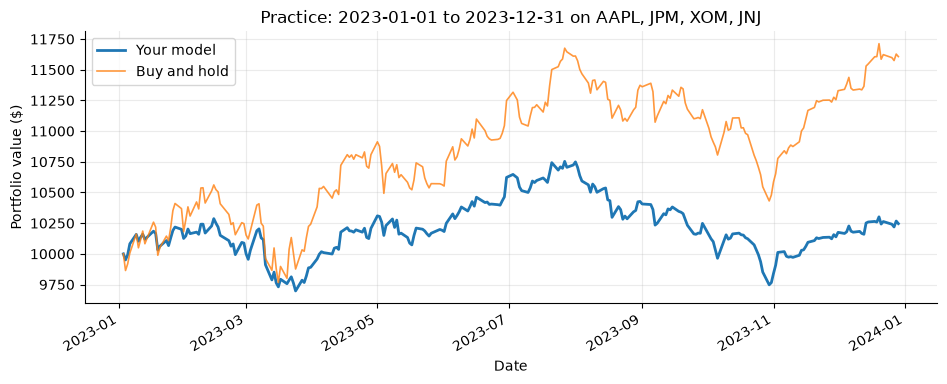

Saved as attempt #1. Sharpe: 0.33


0.33483960293983017

In [8]:
# Use the original organizer's deterministic-input contract check.
display(harness.smoke_check_predict(predict))

# Save one official attempt for the exact frozen predictor being exported.
practice_score(predict, note="Trained four-feature logistic regression; frozen 2015–2022 fit, 2023 practice")


## 7 · Save both required submission files

The next cell calls the unchanged organizer export function. It validates the
predictor in a fresh Python process and saves the `.pkl` bundle. Submit that
file **and this executed `.ipynb`** to the organizer's shared folder. In Colab,
use **File → Download → Download .ipynb** for the notebook.

Review the measured results and explanation before submitting. The model stays
trained through 2022; do not relabel 2023 practice as an untouched final test.


In [9]:
# Exact organizer submission call; its implementation remains in setup.
save_submission(predict)


✅ Signal_Lab_submission.pkl saved and checked (0.1 MB).
   Test position on sample data: 0.5
   File location: trading_competition/Signal_Lab_submission.pkl


PosixPath('trading_competition/Signal_Lab_submission.pkl')